# 03. Baseline Model - Binary Classification Approach

## Overview
This notebook builds proper baselines for the Deezer music recommendation task.

**Problem Formulation:** Binary classification - predict `is_listened` (0 or 1) for each user-song pair

**Key Differences from 02_baseline_model.ipynb:**
- Uses cleaned preprocessed data (your feature engineering)
- Treats this as **classification**, not retrieval (matches Kaggle evaluation)
- Proper temporal train/test split (no data leakage)
- Consistent evaluation metrics (AUC, Precision, Recall, F1)
- Multiple baselines from simple to sophisticated

## 1. Setup & Data Loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, roc_curve
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
RANDOM_STATE = 42
print('Libraries loaded')

Libraries loaded


### Load Preprocessed Data

In [ ]:
try:
    from google.colab import drive
    #drive.mount('/content/gdrive')
    #base_path = '/content/gdrive/MyDrive/Recommender Systems (Project)/'
    drive.mount('/content/drive', force_remount=True)
    base_path = '/content/drive/MyDrive/Music Recommender System/Recommender Systems (Project)/'
except:
    base_path = './'
    print('Using local path')

df_train = pd.read_csv(base_path + 'train_processed.csv') # cleaned but no feature variables
df_test = pd.read_csv(base_path + 'test_processed.csv') # kaggel test data

print(f'Train shape: {df_train.shape}')
print(f'Test shape: {df_test.shape}')
print(f'Train columns: {list(df_train.columns)}')

Mounted at /content/drive
Train shape: (7558184, 15)
Test shape: (19918, 21)
Train columns: ['genre_id', 'ts_listen', 'media_id', 'album_id', 'context_type', 'release_date', 'platform_name', 'platform_family', 'media_duration', 'listen_type', 'user_gender', 'user_id', 'artist_id', 'user_age', 'is_listened']


In [ ]:
# Load chronologically split data (see 02_preprocessing -colab)

train_data = pd.read_csv(base_path + 'train_data.csv')

val_data = pd.read_csv(base_path + 'val_data.csv')

test_data = pd.read_csv(base_path + 'test_data.csv')

print(train_data.shape)
print(val_data.shape)
print(test_data.shape)

(6046547, 21)
(755818, 21)
(755819, 21)


In [ ]:
train_data.info()
val_data.info()
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6046547 entries, 0 to 6046546
Data columns (total 21 columns):
 #   Column               Dtype
---  ------               -----
 0   genre_id             int64
 1   media_id             int64
 2   album_id             int64
 3   context_type         int64
 4   platform_name        int64
 5   platform_family      int64
 6   media_duration       int64
 7   listen_type          int64
 8   user_gender          int64
 9   user_id              int64
 10  artist_id            int64
 11  user_age             int64
 12  is_listened          int64
 13  listen_hour          int64
 14  listen_dayofweek     int64
 15  listen_month         int64
 16  song_age_days        int64
 17  user_listen_count    int64
 18  item_listen_count    int64
 19  artist_listen_count  int64
 20  genre_listen_count   int64
dtypes: int64(21)
memory usage: 968.8 MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 755818 entries, 0 to 755817
Data columns (total 21 columns):

## 2. Exploratory Data Analysis

### Target Distribution

In [ ]:
print('=' * 60)
print('TARGET VARIABLE: is_listened')
print('=' * 60)

listened_counts = df_train['is_listened'].value_counts()
listened_pct = df_train['is_listened'].value_counts(normalize=True) * 100

print(f'Class 0 (not listened): {listened_counts[0]:,} ({listened_pct[0]:.2f}%)')
print(f'Class 1 (listened):     {listened_counts[1]:,} ({listened_pct[1]:.2f}%)')
print(f'Imbalance Ratio: {listened_counts[0] / listened_counts[1]:.2f}:1')
print('\nImportant: Use AUC as primary metric, not accuracy!')

TARGET VARIABLE: is_listened
Class 0 (not listened): 2,388,273 (31.60%)
Class 1 (listened):     5,169,911 (68.40%)
Imbalance Ratio: 0.46:1

Important: Use AUC as primary metric, not accuracy!


### Feature Overview

In [ ]:
print('\n' + '=' * 60)
print('FEATURES AVAILABLE')
print('=' * 60)

feature_cols = [
    'genre_id', 'context_type', 'platform_name', 'platform_family',
    'listen_type', 'user_gender',
    'listen_hour', 'listen_dayofweek', 'listen_month',
    'media_duration', 'user_age', 'song_age_days',
    'user_listen_count', 'item_listen_count',
    'artist_listen_count', 'genre_listen_count'
]

print(f'\nFeatures selected: {len(feature_cols)}')
print(feature_cols)


FEATURES AVAILABLE

Features selected: 16
['genre_id', 'context_type', 'platform_name', 'platform_family', 'listen_type', 'user_gender', 'listen_hour', 'listen_dayofweek', 'listen_month', 'media_duration', 'user_age', 'song_age_days', 'user_listen_count', 'item_listen_count', 'artist_listen_count', 'genre_listen_count']


## 3. Prepare Data for Modeling

In [ ]:
X_train = train_data[feature_cols].copy()
y_train = train_data['is_listened'].copy()

X_val = val_data[feature_cols].copy()
y_val = val_data['is_listened'].copy()

X_test = test_data[feature_cols].copy()
y_test = test_data['is_listened'].copy()

print(f'X_train: {X_train.shape}')
print(f'X_val: {X_val.shape}')
print(f'X_test: {X_test.shape}')
print('Ready for modeling')

X_train: (6046547, 16)
X_val: (755818, 16)
X_test: (755819, 16)
Ready for modeling


## 4. Evaluation Function

In [ ]:
def evaluate_model(y_true, y_pred_proba, y_pred_binary=None, model_name='Model'):
    if y_pred_binary is None:
        y_pred_binary = (y_pred_proba >= 0.5).astype(int)

    metrics = {
        'auc': roc_auc_score(y_true, y_pred_proba),
        'precision': precision_score(y_true, y_pred_binary, zero_division=0),
        'recall': recall_score(y_true, y_pred_binary, zero_division=0),
        'f1': f1_score(y_true, y_pred_binary, zero_division=0),
    }

    print(f'\n{"="*60}')
    print(f'{model_name}')
    print(f'{"="*60}')
    print(f'  AUC:       {metrics["auc"]:.4f}')
    print(f'  Precision: {metrics["precision"]:.4f}')
    print(f'  Recall:    {metrics["recall"]:.4f}')
    print(f'  F1-Score:  {metrics["f1"]:.4f}')

    return metrics

## 6. Baselines

### Baseline 1: Popularity-Based

In [ ]:
item_stats = train_data.groupby('media_id').agg({
    'is_listened': ['sum', 'count']
}).reset_index()

item_stats.columns = ['media_id', 'listens', 'total']
item_stats['listen_rate'] = item_stats['listens'] / item_stats['total']

y_pred_pop = test_data['media_id'].map(
    item_stats.set_index('media_id')['listen_rate']
).fillna(train_data['is_listened'].mean())

pop_metrics = evaluate_model(y_test, y_pred_pop, model_name='Baseline 1: Popularity-Based')


Baseline 1: Popularity-Based
  AUC:       0.6055
  Precision: 0.6523
  Recall:    0.9521
  F1-Score:  0.7742


### Baseline 2: Logistic Regression (Popularity Features)

In [ ]:
popularity_features = ['user_listen_count', 'item_listen_count',
                        'artist_listen_count', 'genre_listen_count']

X_train_pop = X_train[popularity_features].copy()
X_test_pop = X_test[popularity_features].copy()

scaler_pop = StandardScaler()
X_train_pop_scaled = scaler_pop.fit_transform(X_train_pop)
X_test_pop_scaled = scaler_pop.transform(X_test_pop)

lr_pop = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, n_jobs=-1)
lr_pop.fit(X_train_pop_scaled, y_train)

y_pred_lr_pop = lr_pop.predict_proba(X_test_pop_scaled)[:, 1]

lr_pop_metrics = evaluate_model(y_test, y_pred_lr_pop,
                                 model_name='Baseline 2: LR (Popularity Features)')


Baseline 2: LR (Popularity Features)
  AUC:       0.5587
  Precision: 0.6420
  Recall:    1.0000
  F1-Score:  0.7820


### Baseline 3: Logistic Regression (All Features)

In [ ]:
scaler_all = StandardScaler()
X_train_scaled = scaler_all.fit_transform(X_train)
X_test_scaled = scaler_all.transform(X_test)

lr_all = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, n_jobs=-1)
lr_all.fit(X_train_scaled, y_train)

y_pred_lr_all = lr_all.predict_proba(X_test_scaled)[:, 1]

lr_all_metrics = evaluate_model(y_test, y_pred_lr_all,
                                model_name='Baseline 3: LR (All Features)')


Baseline 3: LR (All Features)
  AUC:       0.6527
  Precision: 0.6647
  Recall:    0.9424
  F1-Score:  0.7795


### Baseline 4: LightGBM (Optional)

In [ ]:
try:
    import lightgbm as lgb

    lgb_model = lgb.LGBMClassifier(
        n_estimators=100,
        learning_rate=0.05,
        num_leaves=31,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1,
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum()
    )

    lgb_model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.log_evaluation(period=0)]
    )

    y_pred_lgb = lgb_model.predict_proba(X_test)[:, 1]

    lgb_metrics = evaluate_model(y_test, y_pred_lgb,
                                model_name='Baseline 4: LightGBM')

    print('\nTop Features:')
    importance_df = pd.DataFrame({
        'feature': feature_cols,
        'importance': lgb_model.feature_importances_
    }).sort_values('importance', ascending=False)
    print(importance_df.head(10).to_string(index=False))

except ImportError:
    print('LightGBM not installed. Skipping Baseline 4.')
    lgb_metrics = None


Baseline 4: LightGBM
  AUC:       0.6777
  Precision: 0.7833
  Recall:    0.4725
  F1-Score:  0.5895

Top Features:
            feature  importance
  user_listen_count         788
       context_type         567
           user_age         376
        listen_hour         230
  item_listen_count         197
      platform_name         148
artist_listen_count         132
        listen_type          97
           genre_id          88
    platform_family          84


## 7. Results Summary

In [ ]:
results = {
    'Baseline 1: Popularity': pop_metrics,
    'Baseline 2: LR (Pop)': lr_pop_metrics,
    'Baseline 3: LR (All)': lr_all_metrics,
}

if lgb_metrics is not None:
    results['Baseline 4: LightGBM'] = lgb_metrics

results_df = pd.DataFrame(results).T.round(4)

print('\n' + '='*80)
print('BASELINE COMPARISON (Test Set)')
print('='*80)
print(results_df.to_string())
print('\nPrimary Metric: AUC (for imbalanced classification)')


BASELINE COMPARISON (Test Set)
                           auc  precision  recall      f1
Baseline 1: Popularity  0.6055     0.6523  0.9521  0.7742
Baseline 2: LR (Pop)    0.5587     0.6420  1.0000  0.7820
Baseline 3: LR (All)    0.6527     0.6647  0.9424  0.7795
Baseline 4: LightGBM    0.6777     0.7833  0.4725  0.5895

Primary Metric: AUC (for imbalanced classification)


In [ ]:
results_df.to_csv(base_path + "baseline_results_nb03.csv")
print("Saved:", base_path + "baseline_results_nb03.csv")

## 8. ROC Curves

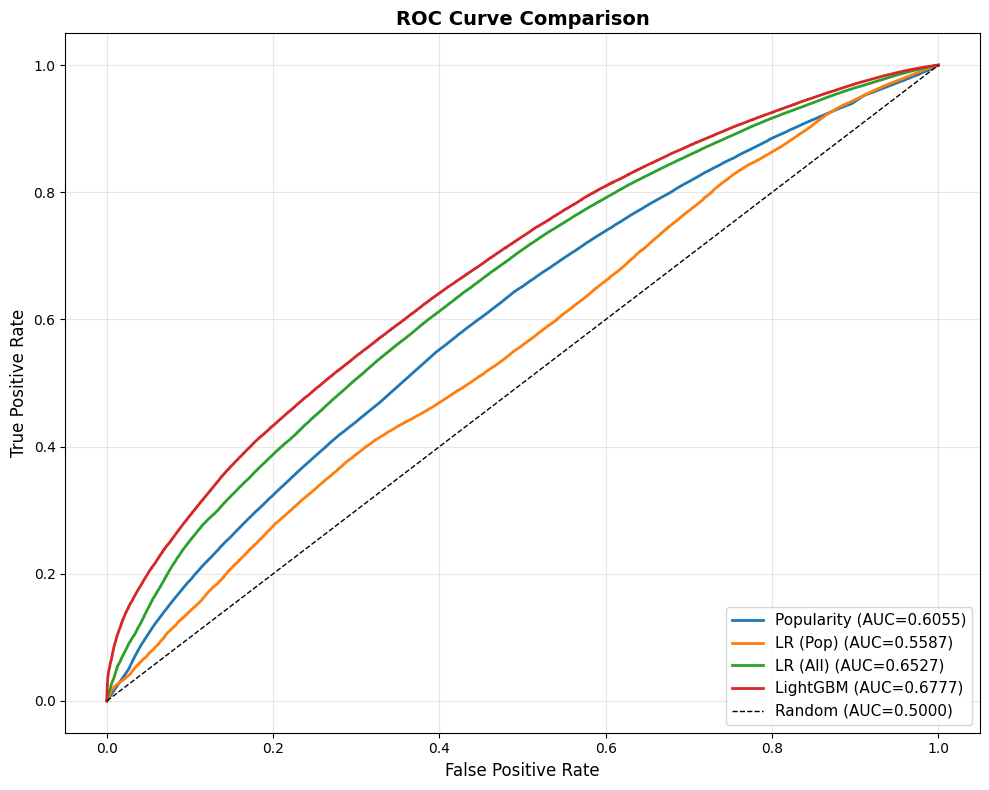

In [ ]:
plt.figure(figsize=(10, 8))

predictions = {
    'Popularity': y_pred_pop,
    'LR (Pop)': y_pred_lr_pop,
    'LR (All)': y_pred_lr_all,
}

if lgb_metrics is not None:
    predictions['LightGBM'] = y_pred_lgb

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
for (name, y_pred), color in zip(predictions.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.4f})', linewidth=2, color=color)

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC=0.5000)')

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve Comparison', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Next Steps

  **Step 1: Diagnostic Analysis (1-2 hours)**

  1. Feature correlation analysis
  2. Feature importance from LightGBM
  3. Confusion matrix analysis
  4. Check if test set is biased (all from same artists, genres, etc.)

  **Step 2: Feature Engineering - Collaborative Signals (Priority!)**

  - Instead of generic features, build:
  - User embeddings from matrix factorization
  - Item embeddings from matrix factorization
  - User-artist affinity
  - User-genre preference
  - Context similarity (platform patterns, time patterns per user)
  - Recommendation-specific features

  **Step 3: Try Hybrid Approach**

  - LightGBM on: [content features] + [user embeddings] + [item embeddings]
  - This combines what your colleague tried (embeddings) with your approach (features)

  **Step 4: ONLY THEN - Hyperparameter Tuning**

  - Once you have better features, tune the best model

  **Step 5: Ensemble & Submission**

  - Combine multiple models

## 1. Understand WHY AUC is so weak

In [ ]:
# Check: Are the features actually correlated with is_listened?
print("Feature correlation with is_listened:")
correlations = df_train[feature_cols +
['is_listened']].corr()['is_listened'].sort_values(ascending=False)
print(correlations)

# Check: What % of variance do we explain?
# If features have near-zero correlation, no model will help

Feature correlation with is_listened:
is_listened            1.000000
platform_name          0.170944
platform_family        0.160545
user_age               0.081005
context_type           0.058106
user_listen_count      0.036679
genre_listen_count     0.035126
artist_listen_count    0.004237
listen_dayofweek       0.003321
media_duration         0.003224
item_listen_count     -0.005198
genre_id              -0.009306
listen_month          -0.011183
song_age_days         -0.018201
user_gender           -0.035228
listen_hour           -0.038166
listen_type           -0.119851
Name: is_listened, dtype: float64


## 2. Reconsider the Approach
Earlier used **matrix factorization (ALS)** (by Samrii). That failed (AUC worse than popularity).

I'm using **feature-based classification (Logistic Regression, LightGBM)**.

Question: Should we combine both?

What if:
1. Learned user embeddings (matrix factorization)
2. Learned item embeddings (matrix factorization)
3. Combined with features (demographics, temporal, etc.)
4. Predicted with that combination?

This is what top Kaggle solutions do: hybrid collaborative + content-based